In [1]:
%matplotlib inline

import os
from pathlib import Path

import numpy as np
import scipy.stats as st
from scipy.stats import spearmanr, sem
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica Neue']

In [2]:
DATA_DIR = Path.cwd().parent / "data"
FIG_DIR = Path.cwd().parent / "figures-new"

MODELS = {
    "woodbury_full": "DFR-MB",
    "woodbury_td":   "DFR-TD",
    "sr_td":         "SR-TD",
    "sr_sf":         "SR-SF",
}
COLORS = {
    "woodbury_full": "black",
    "woodbury_td":   "cornflowerblue",
    "sr_td":         "lightsteelblue",
    "sr_sf":         "slategrey",
}

In [3]:
def run_curves(z, key, cost_scale=-0.1, variance_type='ci'):
    """
    Record array -> (mean across seeds, variance/spread across seed-means).
    
    variance_type options:
      - 'ci' : 95% Confidence Interval (Recommended for N=5)
      - 'std': Standard Deviation (Shows true spread of the seeds)
      - 'sem': Standard Error of the Mean (Your original method)
    """
    a = z[key].astype(float)
    
    # 1. Average over the 200 evaluation pairs to get the expected cost per seed
    axes = tuple(i for i in range(a.ndim) if i not in (0, a.ndim - 2))
    run_means = cost_scale * a.mean(axis=axes)  # Shape: (n_runs, n_checkpoints)
    
    # 2. Calculate the mean across the 5 seeds
    mean_across_seeds = run_means.mean(axis=0)
    
    n_runs = run_means.shape[0]
    std_across_seeds = run_means.std(axis=0, ddof=1)
    
    # 3. Calculate the shaded region based on variance preference
    if variance_type == 'std':
        spread = std_across_seeds
        
    elif variance_type == 'sem':
        spread = std_across_seeds / np.sqrt(n_runs)
        
    elif variance_type == 'ci':
        # Calculate 95% CI using Student's t-distribution for small sample sizes
        sem = std_across_seeds / np.sqrt(n_runs)
        # st.t.ppf gets the critical value. For 95% CI and N=5, df=4.
        t_critical = st.t.ppf((1 + 0.95) / 2., n_runs - 1) 
        spread = sem * t_critical
        
    else:
        raise ValueError("variance_type must be 'ci', 'std', or 'sem'")
        
    return mean_across_seeds, spread

# Environment visualizations

In [3]:
plt.rcParams['axes.linewidth'] = 3.0

## Four-room

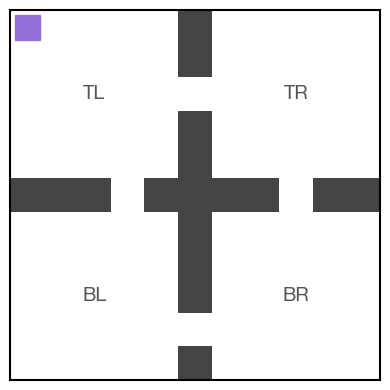

In [156]:
# save_path = FIG_DIR / 'mazes/four-room.png'
save_path = None

ROWS, COLS = 11, 11

# Compute wall and doorway states exactly as make_four_room does
h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set    = set(h_wall + v_wall)
doorway_set = {2*COLS+5, 5*COLS+3, 9*COLS+5, 5*COLS+8}  # 27, 58, 104, 63

START = 0   # state (0,0) — TL corner

# Build grid image: 0 = room, 1 = wall, 2 = doorway
grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(4, 4))

cmap = ListedColormap(["white", "#444444", "#6abf69"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, origin='upper', interpolation='nearest')

# Grid lines
# for x in range(COLS + 1):
#     ax.axvline(x - 0.5, color='grey', lw=0.4)
# for y in range(ROWS + 1):
#     ax.axhline(y - 0.5, color='grey', lw=0.4)

# Mark START state
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=5)

# # Annotate doorways with state numbers
# for s in sorted(doorway_set):
#     r, c = divmod(s, COLS)
#     ax.text(c, r, str(s), ha='center', va='center',
#             fontsize=7, color='white', fontweight='bold')

# Room labels
for label, rr, rc in [("TL", 2, 2), ("TR", 2, 8), ("BL", 8, 2), ("BR", 8, 8)]:
    ax.text(rc, rr, label, ha='center', va='center',
            fontsize=14, color='#555555', fontweight='bold', alpha=1.0)

# ax.set_xticks(np.arange(COLS))
# ax.set_yticks(np.arange(ROWS))
# ax.set_title("Four-room environment", fontsize=14)
ax.tick_params(length=0)

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/var/folders/sf/4_xlxj4j2r1_sx5v07843wbw0000gn/T/ipykernel_19534/1954853527.py:45: SyntaxWarning: invalid escape sequence '\m'
  ax.text(c, r, f'$\mathrm{{r}}_{label}$', ha='center', va='center',


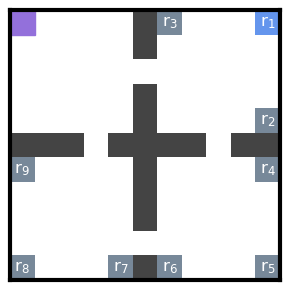

In [218]:
save_path = FIG_DIR / 'mazes/four-room-goals.png'
# save_path = None

ROWS, COLS = 11, 11

h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set = set(h_wall + v_wall)

grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(3, 3))

cmap = ListedColormap(["white", "#444444"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=1, origin='upper', interpolation='nearest')

CORNER_BLUE = 'cornflowerblue'
CORNER_GRAY = 'lightslategray'

corner_cells = [
    # TR room
    (0, 10, 1),   # <- blue
    (4, 10, 2),
    (0,  6, 3),
    # BR room
    (6, 10, 4),
    (10,10, 5),
    (10, 6, 6),
    # BL room
    (10, 4, 7),
    (10, 0, 8),
    (6,  0, 9),
]

# Mark START state
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=1)

for r, c, label in corner_cells:
    color = CORNER_BLUE if label == 1 else CORNER_GRAY
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=color, zorder=2))
    ax.text(c, r, f'$\mathrm{{r}}_{label}$', ha='center', va='center',
            fontsize=12, color='white', fontweight='bold', zorder=3)

ax.tick_params(length=0)
plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

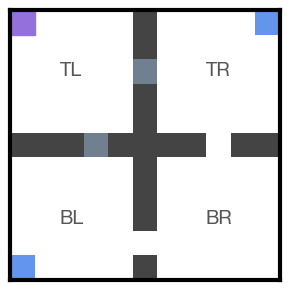

In [220]:
save_path = FIG_DIR / 'mazes/four-room-walls.png'
# save_path = None

ROWS, COLS = 11, 11

h_wall = [5 * COLS + c for c in range(COLS) if c not in (3, 8)]
v_wall = [r * COLS + 5  for r in range(ROWS) if r not in (2, 5, 9)]
wall_set    = set(h_wall + v_wall)
doorway_set = {2*COLS+5, 5*COLS+3, 9*COLS+5, 5*COLS+8}  # 27, 58, 104, 63

START = 0

grid = np.zeros((ROWS, COLS), dtype=float)
for s in wall_set:
    r, c = divmod(s, COLS)
    grid[r, c] = 1.0

fig, ax = plt.subplots(figsize=(3, 3))

cmap = ListedColormap(["white", "#444444"])
ax.imshow(grid, cmap=cmap, vmin=0, vmax=1, origin='upper', interpolation='nearest')

GOAL_COLOR = 'cornflowerblue'
for r, c in [(0, 10), (10, 0)]:
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=GOAL_COLOR, zorder=2))

DOOR_COLOR = 'Slategrey'
for s in [2*COLS+5, 5*COLS+3]:   # states 27, 58
    r, c = divmod(s, COLS)
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=DOOR_COLOR, zorder=2))

# START marker
sr, sc = divmod(START, COLS)
ax.plot(sc, sr, 's', ms=18, color='mediumpurple', zorder=1)

for label, rr, rc in [("TL", 2, 2), ("TR", 2, 8), ("BL", 8, 2), ("BR", 8, 8)]:
    ax.text(rc, rr, label, ha='center', va='center',
            fontsize=14, color='#555555', fontweight='bold', alpha=1.0)

ax.tick_params(length=0)
plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Open-field horizontal barrier

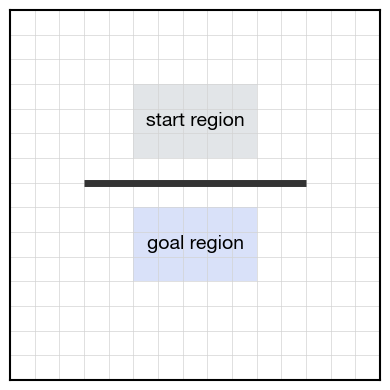

In [153]:
# save_path = FIG_DIR / 'mazes/open-field-H.png'
save_path = None

# Geometry matches plan_open_horizontal.py
ROWS_H, COLS_H  = 15, 15
BARRIER_ROW     = ROWS_H // 2        # 7  — wall sits between rows 6 and 7
COL_START       = 3
COL_END         = 12                 # wall covers cols 3..11

# Evaluation regions
START_ROW_MIN, START_ROW_MAX = 3, 5
START_COL_MIN, START_COL_MAX = 5, 9
GOAL_ROW_MIN,  GOAL_ROW_MAX  = 8, 10
GOAL_COL_MIN,  GOAL_COL_MAX  = 5, 9

fig, ax = plt.subplots(figsize=(4, 4))

# White grid
ax.imshow(np.zeros((ROWS_H, COLS_H)), cmap='Greys', vmin=0, vmax=1,
          origin='upper', interpolation='nearest', aspect='equal')

# Light cell grid
for x in range(COLS_H + 1):
    ax.axvline(x - 0.5, color='lightgrey', lw=0.5)
for y in range(ROWS_H + 1):
    ax.axhline(y - 0.5, color='lightgrey', lw=0.5)

# Shade start region (rows 3–5, cols 5–9)
ax.add_patch(Rectangle(
    (START_COL_MIN - 0.5, START_ROW_MIN - 0.5),
    START_COL_MAX - START_COL_MIN + 1,
    START_ROW_MAX - START_ROW_MIN + 1,
    facecolor='slategrey', alpha=0.2, zorder=0
))

# Shade goal region (rows 8–10, cols 5–9)
ax.add_patch(Rectangle(
    (GOAL_COL_MIN - 0.5, GOAL_ROW_MIN - 0.5),
    GOAL_COL_MAX - GOAL_COL_MIN + 1,
    GOAL_ROW_MAX - GOAL_ROW_MIN + 1,
    facecolor='royalblue', alpha=0.2, zorder=0
))

# Horizontal barrier: thick wall between rows 6 and 7, cols 3..11
ax.plot([COL_START - 0.5, COL_END - 0.5],
        [BARRIER_ROW - 0.5, BARRIER_ROW - 0.5],
        color='#333333', lw=5, solid_capstyle='butt', zorder=3)

ax.set_xticks(np.arange(COLS_H))
ax.set_yticks(np.arange(ROWS_H))
ax.set_xticklabels(np.arange(COLS_H), fontsize=6)
ax.set_yticklabels(np.arange(ROWS_H), fontsize=6)
# ax.set_title("Open-field: horizontal barrier", fontsize=14)
ax.tick_params(length=0)
ax.text((START_COL_MIN + START_COL_MAX) / 2, (START_ROW_MIN + START_ROW_MAX) / 2,
        "start region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')
ax.text((GOAL_COL_MIN + GOAL_COL_MAX) / 2, (GOAL_ROW_MIN + GOAL_ROW_MAX) / 2,
        "goal region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Open-field L barrier

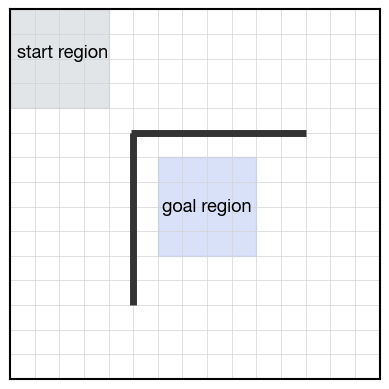

In [154]:
# save_path = FIG_DIR / 'mazes/open-field-L.png'
save_path = None

# Geometry matches plan_open_angle.py
ROWS_L, COLS_L = 15, 15
CORNER_ROW = 5
CORNER_COL = 5
H_END_COL  = 12   # horizontal arm: cols [CORNER_COL, H_END_COL) = 5..11
V_END_ROW  = 12   # vertical arm:   rows [CORNER_ROW, V_END_ROW) = 5..11

fig, ax = plt.subplots(figsize=(4, 4))

# White grid
ax.imshow(np.zeros((ROWS_L, COLS_L)), cmap='Greys', vmin=0, vmax=1,
          origin='upper', interpolation='nearest', aspect='equal')

# Light cell grid lines
for x in range(COLS_L + 1):
    ax.axvline(x - 0.5, color='lightgrey', lw=0.5)
for y in range(ROWS_L + 1):
    ax.axhline(y - 0.5, color='lightgrey', lw=0.5)

# Shade start region (top-left: rows 0..CORNER_ROW-1, cols 0..CORNER_COL-1)
ax.fill_betweenx(
    [-0.5, CORNER_ROW-1 - 0.5],
    -0.5, CORNER_COL-1 - 0.5,
    color='slategrey', alpha=0.2
)

# Shade goal region (bottom-right: rows V_END_ROW..end, cols H_END_COL..end)
ax.fill_betweenx(
    [6 - 0.5, 10 - 0.5],
    6 - 0.5, 10 - 0.5,
    color='royalblue', alpha=0.2
)

# L-shaped barrier: horizontal arm + vertical arm (meet at corner)
wall_kw = dict(color='#333333', lw=5, solid_capstyle='butt', zorder=3)
ax.plot([CORNER_COL - 0.6, H_END_COL - 0.5],
        [CORNER_ROW - 0.5, CORNER_ROW - 0.5], **wall_kw)   # horizontal arm
ax.plot([CORNER_COL - 0.5, CORNER_COL - 0.5],
        [CORNER_ROW - 0.5, V_END_ROW - 0.5],  **wall_kw)   # vertical arm

ax.set_xticks(np.arange(COLS_L))
ax.set_yticks(np.arange(ROWS_L))
ax.set_xticklabels(np.arange(COLS_L), fontsize=6)
ax.set_yticklabels(np.arange(ROWS_L), fontsize=6)
# ax.set_title("Open-field: L-shaped barrier", fontsize=14)
ax.tick_params(length=0)

ax.text(1.65, 1.25, "start region",
        ha='center', va='center', fontsize=13, color='black', alpha=1.0)
ax.text(7.5,7.5, "goal region",
        ha='center', va='center', fontsize=13, color='black', alpha=1.0)

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

## Open-field two horizontal barriers

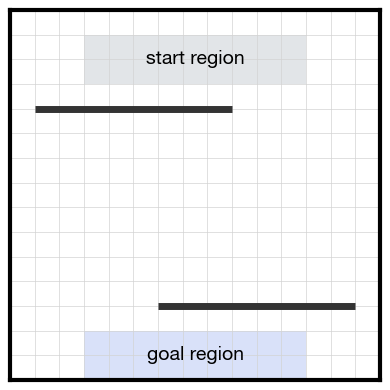

In [10]:
save_path = FIG_DIR / 'mazes/open-field-combined.png'
# save_path = None

ROWS_C, COLS_C = 15, 15
H1_ROW       = 4
H1_COL_START = 1
H1_COL_END   = 9
H2_ROW       = 12
H2_COL_START = 6
H2_COL_END   = 14

# Evaluation regions
START_ROW_MIN, START_ROW_MAX = 1, 2
START_COL_MIN, START_COL_MAX = 3, 11
GOAL_ROW_MIN,  GOAL_ROW_MAX  = 13, 14
GOAL_COL_MIN,  GOAL_COL_MAX  = 3, 11

fig, ax = plt.subplots(figsize=(4, 4))

# White grid
ax.imshow(np.zeros((ROWS_C, COLS_C)), cmap='Greys', vmin=0, vmax=1,
          origin='upper', interpolation='nearest', aspect='equal')

# Light cell grid
for x in range(COLS_C + 1):
    ax.axvline(x - 0.5, color='lightgrey', lw=0.5)
for y in range(ROWS_C + 1):
    ax.axhline(y - 0.5, color='lightgrey', lw=0.5)

# Shade start region (rows 1-2, cols 3-11)
ax.add_patch(Rectangle(
    (START_COL_MIN - 0.5, START_ROW_MIN - 0.5),
    START_COL_MAX - START_COL_MIN + 1,
    START_ROW_MAX - START_ROW_MIN + 1,
    facecolor='slategrey', alpha=0.2, zorder=0
))

# Shade goal region (rows 13-14, cols 3-11)
ax.add_patch(Rectangle(
    (GOAL_COL_MIN - 0.5, GOAL_ROW_MIN - 0.5),
    GOAL_COL_MAX - GOAL_COL_MIN + 1,
    GOAL_ROW_MAX - GOAL_ROW_MIN + 1,
    facecolor='royalblue', alpha=0.2, zorder=0
))

# Two horizontal barriers
wall_kw = dict(color='#333333', lw=5, solid_capstyle='butt', zorder=3)
ax.plot([H1_COL_START - 0.5, H1_COL_END - 0.5],
        [H1_ROW - 0.5, H1_ROW - 0.5], **wall_kw)   # W1: near start
ax.plot([H2_COL_START - 0.5, H2_COL_END - 0.5],
        [H2_ROW - 0.5, H2_ROW - 0.5], **wall_kw)   # W2: near goal

ax.set_xticks(np.arange(COLS_C))
ax.set_yticks(np.arange(ROWS_C))
ax.set_xticklabels(np.arange(COLS_C), fontsize=6)
ax.set_yticklabels(np.arange(ROWS_C), fontsize=6)
# ax.set_title("Open-field: two horizontal barriers", fontsize=14)
ax.tick_params(length=0)
ax.text((START_COL_MIN + START_COL_MAX) / 2, (START_ROW_MIN + START_ROW_MAX) / 2,
        "start region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')
ax.text((GOAL_COL_MIN + GOAL_COL_MAX) / 2, (GOAL_ROW_MIN + GOAL_ROW_MAX) / 2,
        "goal region", ha='center', va='center', fontsize=14, color='black', fontweight='bold')

plt.xticks([])
plt.yticks([])

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

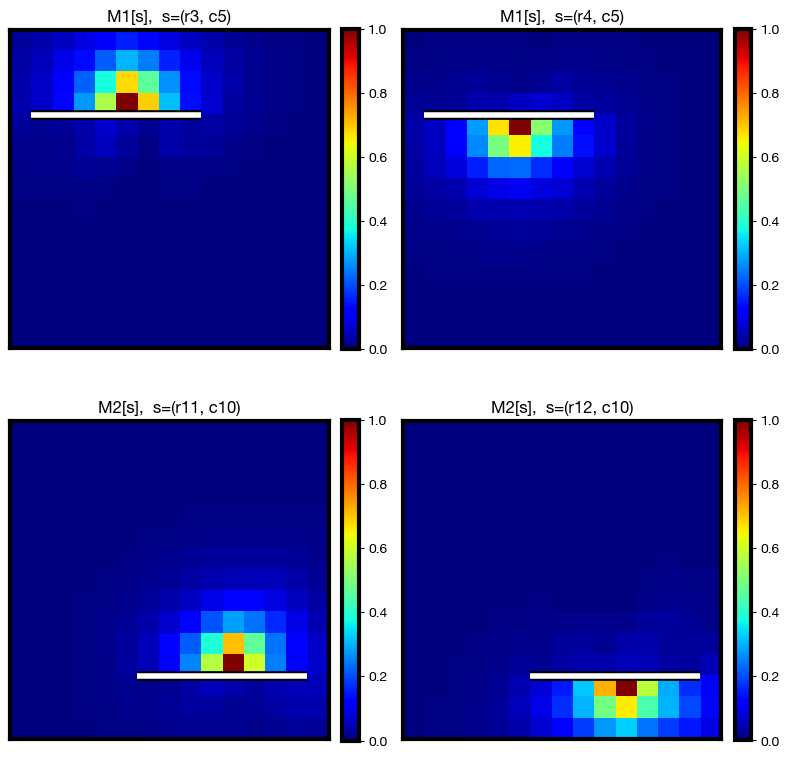

In [35]:
# --- Color scale (shared across all panels) --------------------------------
VMIN, VMAX = 0.0, 1.0        # set both to None for per-plot autoscale

# --- Load saved TD operators (feature-space, k×k) --------------------------
import matplotlib.patheffects as pe
d = np.load(DATA_DIR / "planning_open" / "combine" / "M1_M2_td.npz")
M1_td, M2_td = d["M1_td"], d["M2_td"]

# --- Rebuild F so we can map to space: D ≈ F @ M @ F.T ----------------------
from utils import create_transition_open, get_complete_DR
from models import build_features
ROWS = COLS = 15

D_os = get_complete_DR(T=create_transition_open(shape=(ROWS, COLS)))
D_os = (D_os + D_os.T) / 2
F = build_features(D_os, k=ROWS * COLS)[0]

D1 = F @ M1_td @ F.T          # spatial DR for the start-barrier operator
D2 = F @ M2_td @ F.T          # spatial DR for the goal-barrier operator

# --- Barrier geometry (must match plan_open_combined.py) -------------------
H1_ROW, H1_COL_START, H1_COL_END = 4, 1, 9     # wall between rows 3&4, cols 1..8
H2_ROW, H2_COL_START, H2_COL_END = 12, 6, 14   # wall between rows 11&12, cols 6..13

rc = lambda r, c: r * COLS + c
mid1 = (H1_COL_START + H1_COL_END) // 2
mid2 = (H2_COL_START + H2_COL_END) // 2

# states next to each wall, one cell clear of it: up one above / down one below
panels = [
    ("M1", D1, [rc(H1_ROW - 1, mid1), rc(H1_ROW + 0, mid1)], (H1_ROW, H1_COL_START, H1_COL_END)),
    ("M2", D2, [rc(H2_ROW - 1, mid2), rc(H2_ROW + 0, mid2)], (H2_ROW, H2_COL_START, H2_COL_END)),
]

# --- Plot D[s] reshaped to the maze ----------------------------------------
ncols = max(len(p[2]) for p in panels)
fig, axes = plt.subplots(len(panels), ncols, figsize=(4 * ncols, 4 * len(panels)), squeeze=False)
for row, (name, D, s_list, (wr, wcs, wce)) in enumerate(panels):
    for col in range(ncols):
        ax = axes[row][col]
        if col >= len(s_list):
            ax.axis('off'); continue
        s = s_list[col]; r, c = divmod(s, COLS)
        im = ax.imshow(D[s].reshape(ROWS, COLS), cmap='jet', origin='upper',
                       vmin=VMIN, vmax=VMAX)
        ax.plot([wcs - 0.5, wce - 0.5], [wr - 0.5, wr - 0.5],
                color='white', lw=4, solid_capstyle='butt', zorder=3,
                path_effects=[pe.Stroke(linewidth=7, foreground='black'), pe.Normal()])  # wall
        # ax.plot(c, r, 'c*', ms=16)                                                 # query state s
        ax.set_title(f"{name}[s],  s=(r{r}, c{c})")
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


# Reconstruction loss

In [3]:
plt.rcParams['axes.linewidth'] = 1.5

In [4]:
recon_dir = DATA_DIR / "recon"

data      = np.load(recon_dir / 'recon_errors.npz')
k_values  = data['k_values'].tolist()

In [42]:
data

NpzFile '/Users/abizzle/Research/Compositional-Maps/data/recon/recon_errors.npz' with keys: k_values, 10_steps, 10_frob, 10_mean, 10_median...

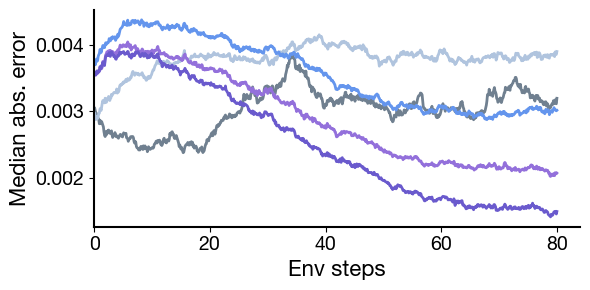

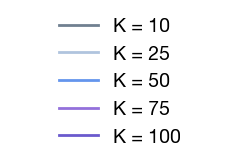

In [10]:
recon_dir = DATA_DIR / "recon"

# save_path = FIG_DIR / 'reconstruction/recon_median.png'
save_path = None

data      = np.load(recon_dir / 'recon_errors.npz')
k_values  = data['k_values'].tolist()

# Override with a custom list of colors, or leave None for viridis default.
RECON_COLORS = ['slategrey', 'lightsteelblue', 'cornflowerblue', 'mediumpurple', 'slateblue']
# RECON_COLORS = None

colors = (RECON_COLORS if RECON_COLORS is not None
          else plt.cm.viridis(np.linspace(0.1, 0.9, len(k_values))))

fig, ax = plt.subplots(figsize=(6, 3))

for k, color in zip(k_values, colors):
    steps  = data[f'{k}_steps'] / 1_0000
    median = data[f'{k}_median']
    ax.plot(steps, median, color=color, lw=2, label=f'K = {k}')

ax.set_xlabel('Env steps', fontsize=16)
ax.set_ylabel('Median abs. error', fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xlim(left=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()
# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

save_path_leg = FIG_DIR / 'reconstruction/recon_legend.png'
if save_path_leg is not None:
    plt.savefig(save_path_leg, bbox_inches='tight', dpi=300)

plt.show()

# Planning

In [4]:
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

## Open-Field

### Horizontal

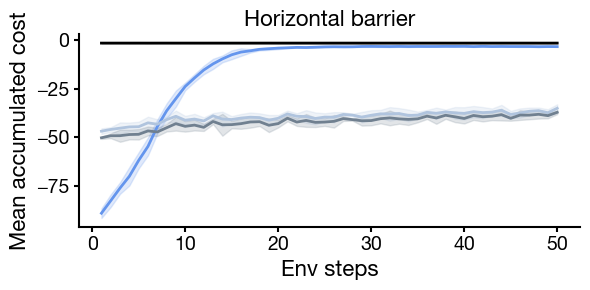

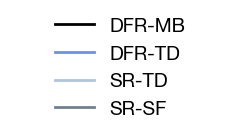

In [5]:
save_path = FIG_DIR / 'planning/plan_open_H.png'
# save_path = None

data = np.load(DATA_DIR / "planning_open" / "horizontal" / "learning_curves_multiseed.npz")

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(6, 3))

for key, label in MODELS.items():
    mean, sem_plt = run_curves(data, key)

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem_plt, mean + sem_plt,
                    color=COLORS[key], alpha=0.2)

ax.set_xlabel("Env steps", fontsize=16)
ax.set_ylabel("Mean accumulated cost", fontsize=16)
ax.set_title("Horizontal barrier", fontsize=16)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

# save_path = FIG_DIR / 'legend.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

### L-barrier

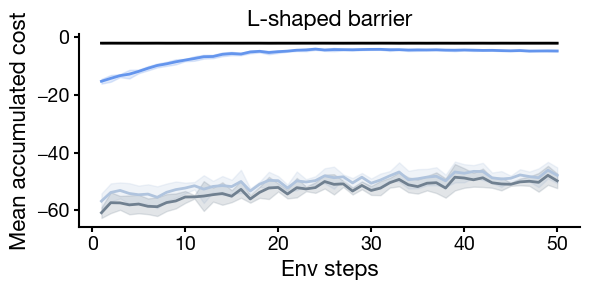

In [6]:
save_path = FIG_DIR / 'planning/plan_open_L.png'
# save_path = None

data = np.load(DATA_DIR / "planning_open" / "angle" / "learning_curves_multiseed.npz")

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(6, 3))

for key, label in MODELS.items():
    mean, sem_plt = run_curves(data, key)

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - sem_plt, mean + sem_plt,
                    color=COLORS[key], alpha=0.2)

ax.set_xlabel("Env steps", fontsize=16)
ax.set_ylabel("Mean accumulated cost", fontsize=16)
ax.set_title("L-shaped barrier", fontsize=16)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

### Combined

In [5]:
data = np.load(DATA_DIR / "planning_open" / "combine" / "learning_curves_combine.npz")

In [6]:
MODELS = {
    "woodbury_full_exact": "Model-based (exact)",
    "dfr_td_combined":     "DFR-TD (M₁+M₂−I)",
    "dfr_td_M1_only":      "DFR-TD (M₁ only)",
    "dfr_td_M2_only":      "DFR-TD (M₂ only)",
}
COLORS = {
    "woodbury_full_exact": "black",
    "dfr_td_combined":     "cornflowerblue",
    "dfr_td_M1_only":      "lightsteelblue",
    "dfr_td_M2_only":      "slategrey",
}

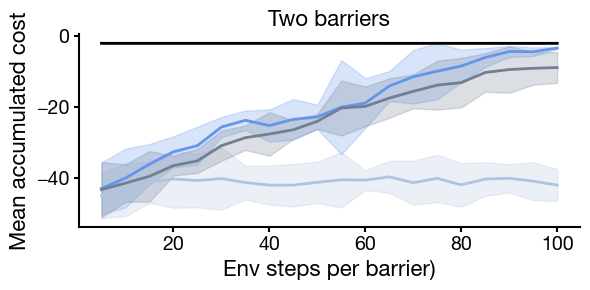

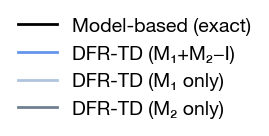

In [ ]:
dir_path = DATA_DIR / "planning_open" / "combine" / "slow"
loaded_data = {
    file.name: np.load(file) 
    for file in dir_path.glob("*.npz")
}
data = {"checkpoint_steps": zs[0]["checkpoint_steps"]}
for key in MODELS:
    data[key] = np.stack([z[key] for z in zs])      # (5, n_checkpoints, n_trials)

# save_path = FIG_DIR / 'planning/plan_open_combine.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(6, 3))

for key, label in MODELS.items():
    mean, band = run_curves(data, key)

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - band, mean + band,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps per barrier)", fontsize=16)
ax.set_ylabel("Mean accumulated cost", fontsize=16)
ax.set_title("Two barriers", fontsize=16)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

# save_path = FIG_DIR / 'legend_combine.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

In [37]:
for key, label in MODELS.items():
    mean, band = run_curves(data, key, cost_scale=1.0)
    print(f"{label:<20s} {mean[-1]:8.2f} ± {band[-1]:.2f} steps")

Model-based (exact)     21.35 ± 0.10 steps
DFR-TD (M₁+M₂−I)        34.72 ± 3.17 steps
DFR-TD (M₁ only)       420.92 ± 44.49 steps
DFR-TD (M₂ only)        89.64 ± 43.10 steps


## Four-Room

### Changing goal

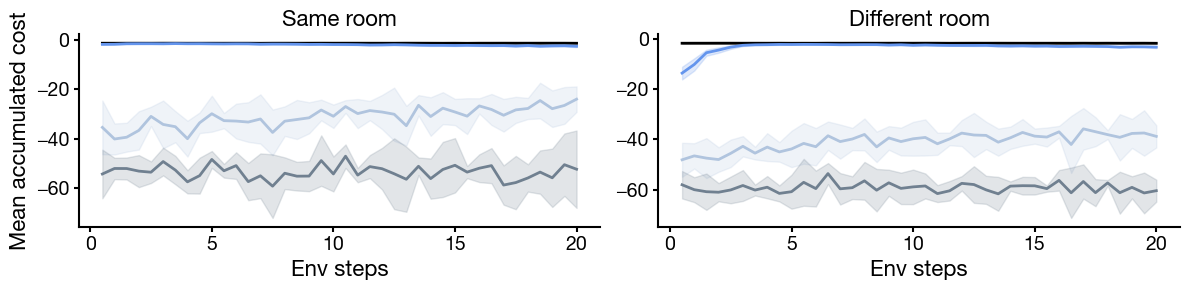

In [14]:
data_goal = np.load(DATA_DIR / "planning_4room" / "goal" / "learning_curves_multiseed.npz")

# save_path = FIG_DIR / 'planning/plan_4room_goal.png'
save_path = None

steps = data_goal["checkpoint_steps"] / 1000

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=False)
titles    = ["Same room", "Different room"]
suffixes  = ["same", "diff"]

for ax, title, suffix in zip(axes, titles, suffixes):
    for key, label in MODELS.items():
        # (n_runs, n_pairs, n_checkpoints, n_trials) -> averaged over pairs and
        # trials within a run, then mean and CI across the run-means
        mean, band = run_curves(data_goal, f"{key}_{suffix}")

        ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
        ax.fill_between(steps, mean - band, mean + band,
                        color=COLORS[key], alpha=0.2)

    ax.set_xlabel("Env steps", fontsize=16)
    if title == "Same room":
        ax.set_ylabel("Mean accumulated cost", fontsize=16)
    ax.set_title(title, fontsize=16)
    ax.tick_params(labelsize=14)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

### Blocked transition

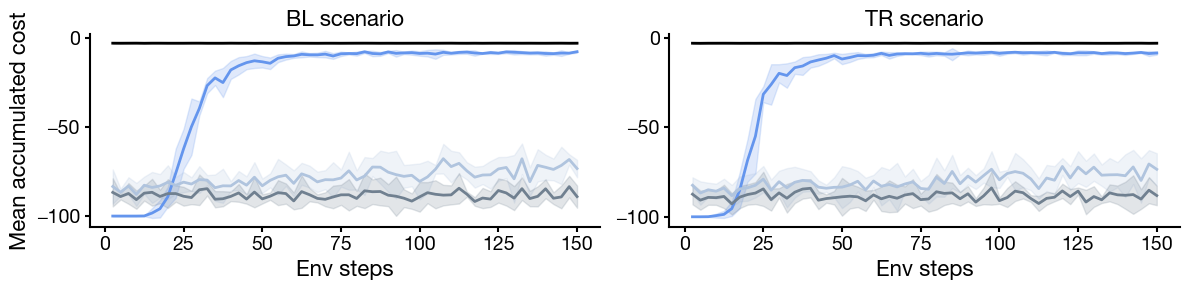

In [6]:
# save_path = FIG_DIR / "planning" / "plan_4room_blocked.png"
save_path = None

data_blocked = np.load(DATA_DIR / "planning_4room" / "blocked" / "learning_curves_multiseed.npz")
steps = data_blocked["checkpoint_steps"] / 1000

# --- learning curves: one panel per scenario ---
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=False)
scenario_titles = {"BL": "BL scenario",
                   "TR": "TR scenario"}

for ax, (scenario_key, title) in zip(axes, scenario_titles.items()):
    for key, label in MODELS.items():
        mean, band = run_curves(data_blocked, f"{key}_{scenario_key}")

        ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
        ax.fill_between(steps, mean - band, mean + band,
                        color=COLORS[key], alpha=0.2)

    ax.set_xlabel("Env steps", fontsize=16)
    if scenario_key == "BL":
        ax.set_ylabel("Mean accumulated cost", fontsize=16)
    ax.set_title(title, fontsize=16)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=14)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# Wernle

In [70]:
# 20x20
# F_divided = np.load(DATA_DIR / 'wernle' / 'F_divided.npy')
# F_merged = np.load(DATA_DIR / 'wernle' / 'F_merged.npy')
# SPLIT = 10
# ROWS = COLS = 20
# N = K = 400

# 30x30
F_divided = np.load(DATA_DIR / 'wernle' / 'F_divided_30.npy')
F_merged = np.load(DATA_DIR / 'wernle' / 'F_merged_30.npy')
SPLIT = 15
ROWS = COLS = 30
N = K = 900

In [71]:
# Wernle sliding correlation
coords = np.array([[r,c] for r in range(ROWS) for c in range(COLS)])
corr = np.full((N,K), np.nan)
for i in range(N):
    d = np.abs(coords - coords[i])
    succ = np.all(d <= 3, axis=1)
    
    same_comp = (coords[:, 0] < SPLIT) == (coords[i, 0] < SPLIT)
    succ = succ & same_comp
    
    if succ.sum() < 4: continue
    for k in range(K):
        b = F_divided[succ,k]; a = F_merged[succ,k]
        if np.std(b)<1e-10 or np.std(a)<1e-10: continue
        corr[i,k] = spearmanr(b,a).correlation

mm = np.nanmean(corr, axis=1).reshape(ROWS,COLS)
rp = np.nanmean(mm, axis=1)

wall_rows = slice(SPLIT-2, SPLIT+2)
distal_rows = list(range(3)) + list(range(ROWS-3, ROWS))

In [72]:
mm.shape

(30, 30)

## Across all grid cells

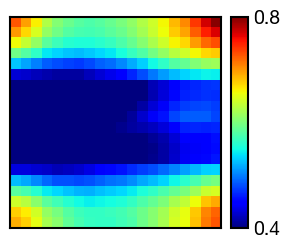

In [ ]:
# save_path = FIG_DIR / "wernle" / "corr_map_all_NEW.png"
save_path = None

fig, ax = plt.subplots(figsize=(3, 3))
vmin = 0.4
vmax = 0.8
im = ax.imshow(mm, cmap='jet', origin='lower', vmin=vmin, vmax=vmax)
ax.set_xticks([])
ax.set_yticks([])
 
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="8%", pad=0.1)
cb = plt.colorbar(im, cax=cax)
cb.set_ticks([vmin, vmax])
cb.ax.tick_params(length=0, labelsize=14)
 
plt.tight_layout()
if save_path is not None:
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

## Specific grid cells

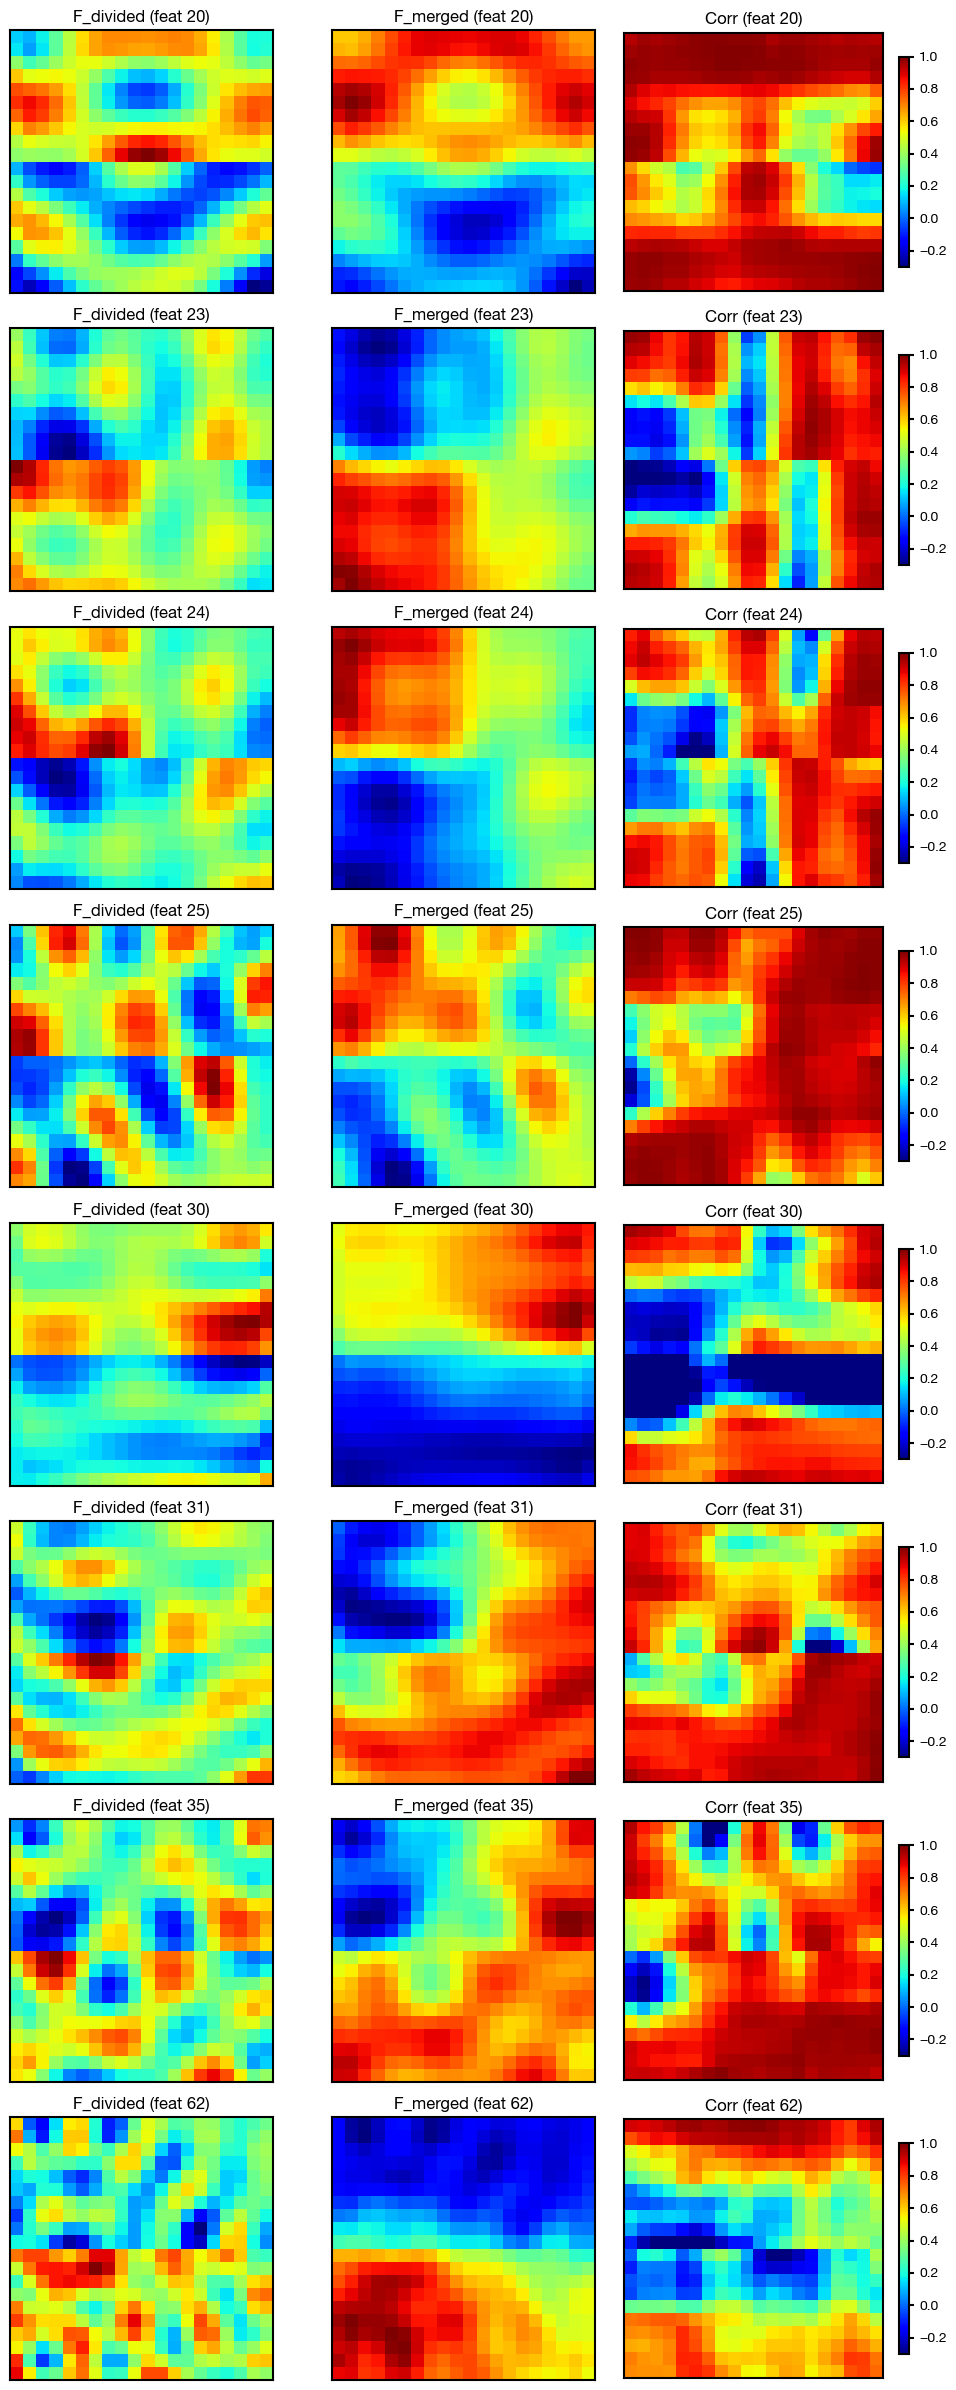

In [53]:

# save_path = FIG_DIR / "wernle" / "corr_map_individual.png"
# save_path = None
vmin = -0.3
vmax = 1.0

feat_indices = [20, 23, 24, 25, 30, 31, 35, 62]
# feat_indices=np.arange(K)
n_feat = len(feat_indices)
fig, axes = plt.subplots(n_feat, 3, figsize=(10, 3*n_feat))
for row, k in enumerate(feat_indices):
    map_b = F_divided[:, k].reshape(ROWS, COLS)
    map_a = F_merged[:, k].reshape(ROWS, COLS)
    map_c = corr[:, k].reshape(ROWS, COLS)
    axes[row,0].imshow(map_b, origin='lower', cmap='jet')
    axes[row,0].set_title(f'F_divided (feat {k})')
    axes[row,1].imshow(map_a, origin='lower', cmap='jet')
    axes[row,1].set_title(f'F_merged (feat {k})')
    im = axes[row,2].imshow(map_c, origin='lower', cmap='jet', vmin=vmin, vmax=vmax)
    axes[row,2].set_title(f'Corr (feat {k})')
    plt.colorbar(im, ax=axes[row,2], shrink=0.8)
    for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
 
plt.tight_layout()
if save_path is not None:
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

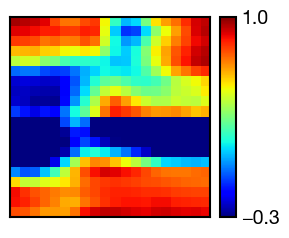

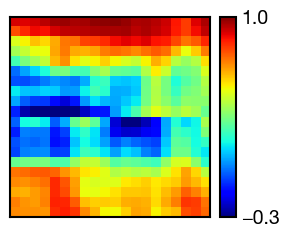

In [54]:
features = [30, 62]
save_dir = FIG_DIR / "wernle"
# save_dir = None
vmin = -0.3
vmax = 1.0
for k in features:
    fig, ax = plt.subplots(figsize=(3, 3))
    map_c = corr[:, k].reshape(ROWS, COLS)
    im = ax.imshow(map_c, cmap='jet', origin='lower', vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="8%", pad=0.1)
    cb = plt.colorbar(im, cax=cax)
    cb.set_ticks([vmin, vmax])
    cb.ax.tick_params(length=0, labelsize=14)
    
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / f"corr_map_individual_f{k}.png", dpi=300, bbox_inches='tight')
    plt.show()

# Model Comparison with Dyna-Q

In [8]:
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

In [9]:

MODELS = {
    "woodbury_feat": "DFR-MB",
    "woodbury_td":   "DFR-TD",
    "dyna_q_k5":     "Dyna-Q-5",
    "dyna_q_k10":    "Dyna-Q-10",
    "dyna_q_k20":    "Dyna-Q-20",
    "dyna_q_k50":    "Dyna-Q-50",
}
cmap_p = plt.get_cmap("Purples")
COLORS_PURPLE = cmap_p(np.linspace(0.5, 0.9, 4))
COLORS = {
    "woodbury_feat": "black",
    "woodbury_td":   "cornflowerblue",
    "dyna_q_k5":     COLORS_PURPLE[0],
    "dyna_q_k10":    COLORS_PURPLE[1],
    "dyna_q_k20":    COLORS_PURPLE[2],
    "dyna_q_k50":    COLORS_PURPLE[3],
}


## Horizontal

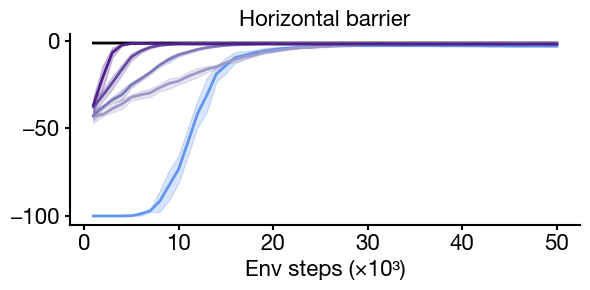

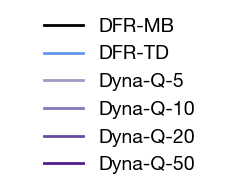

In [10]:
data = np.load(DATA_DIR / "planning_open" / "horizontal_mc" / "learning_curves_multiseed.npz")
# save_path = FIG_DIR / 'planning/plan_open_H_MC.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(6, 3))

for key, label in MODELS.items():
    mean, band = run_curves(data, key)

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - band, mean + band,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps (×10³)", fontsize=16)
# ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("Horizontal barrier", fontsize=16)
ax.tick_params(labelsize=16)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14)
ax_leg.axis("off")
plt.tight_layout()

# save_path = FIG_DIR / 'legend_MC.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

## L-Shape

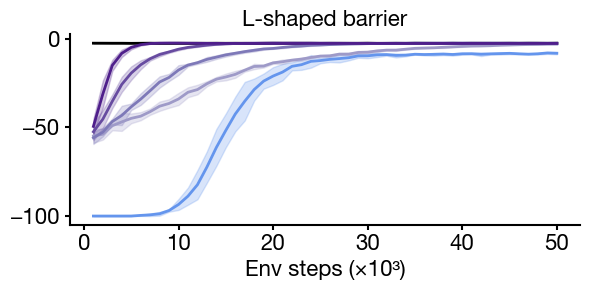

In [12]:
data = np.load(DATA_DIR / "planning_open" / "angle_mc" / "learning_curves_multiseed.npz")
save_path = FIG_DIR / 'planning/plan_open_L_MC.png'
# save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(6, 3))

for key, label in MODELS.items():
    mean, band = run_curves(data, key)

    ax.plot(steps, mean, color=COLORS[key], lw=2, label=label)
    ax.fill_between(steps, mean - band, mean + band,
                    color=COLORS[key], alpha=0.25)

ax.set_xlabel("Env steps (×10³)", fontsize=16)
# ax.set_ylabel("Mean accumulated cost", fontsize=14)
ax.set_title("L-shaped barrier", fontsize=16)
ax.tick_params(labelsize=16)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# Planning with different K

In [5]:
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

In [6]:
K = [50, 75, 100, 125, 150, 175, 200, 225]

cmap_p = plt.get_cmap("Purples")
cmap_b = plt.get_cmap("Blues")
COLORS_BLUE = cmap_b(np.linspace(0.3, 0.5, len(K)//2))
COLORS_PURPLE = cmap_p(np.linspace(0.5, 0.9, len(K)//2+1))
COLORS = np.concatenate((COLORS_BLUE, COLORS_PURPLE))
# COLORS = ["dimgrey", "slategrey", "lightslategrey", "lightsteelblue", 
#           "lavender", "cornflowerblue", "royalblue", "mediumslateblue", "mediumpurple",
# ]

plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5

## Horizontal

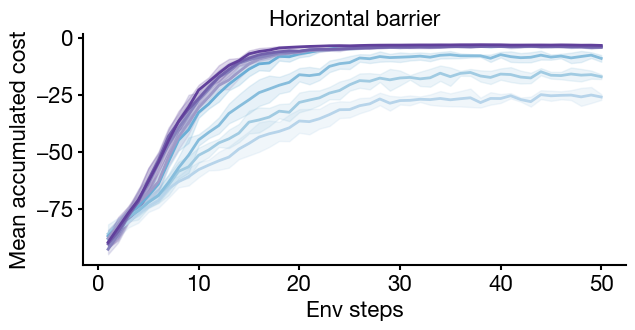

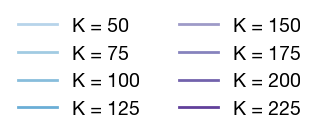

In [7]:
data = np.load(DATA_DIR / "planning_open" / "horizontal" / "num_steps_K_multiseed.npz")

# save_path = FIG_DIR / 'planning/plan_open_Horizontal_K.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(7, 3))

for i, k in enumerate(K):
    model_name = f"woodbury_td_K{k}"
    mean, band = run_curves(data, model_name)

    label = f"K = {K[i]}"
    ax.plot(steps, mean, color=COLORS[i], lw=2, label=label)
    ax.fill_between(steps, mean - band, mean + band,
                    color=COLORS[i], alpha=0.2)

ax.set_xlabel("Env steps", fontsize=16)
ax.set_ylabel("Mean accumulated cost", fontsize=16)
ax.set_title("Horizontal barrier", fontsize=16)
ax.tick_params(labelsize=16)
ax.spines[["top", "right"]].set_visible(False)

# plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()

# --- standalone legend ---
handles, labels = ax.get_legend_handles_labels()
fig_leg, ax_leg = plt.subplots(figsize=(2.5, 1.4))
ax_leg.legend(handles, labels, loc="center", framealpha=0.0, fontsize=14, ncol=2)
ax_leg.axis("off")


# save_path = FIG_DIR / 'legend_K.png'
save_path = None
if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)
    
plt.show()

## Angle

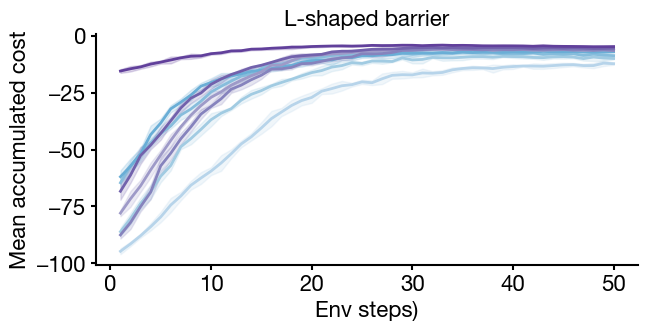

In [ ]:
data = np.load(DATA_DIR / "planning_open" / "angle" / "num_steps_K_multiseed.npz")

# save_path = FIG_DIR / 'planning/plan_open_L_K.png'
save_path = None

steps = data["checkpoint_steps"] / 1000
fig, ax = plt.subplots(figsize=(7, 3))

for i, k in enumerate(K):
    model_name = f"woodbury_td_K{k}"
    mean, band = run_curves(data, model_name)

    label = f"K = {K[i]}"
    ax.plot(steps, mean, color=COLORS[i], lw=2, label=label)
    ax.fill_between(steps, mean - band, mean + band,
                    color=COLORS[i], alpha=0.2)

ax.set_xlabel("Env steps)", fontsize=16)
ax.set_ylabel("Mean accumulated cost", fontsize=16)
ax.set_title("L-shaped barrier", fontsize=16)
ax.tick_params(labelsize=16)
ax.spines[["top", "right"]].set_visible(False)

# plt.tight_layout()

if save_path is not None:
    plt.savefig(save_path, bbox_inches='tight', dpi=300)

plt.show()